## Домашка 4

#### *«Вы видите, но не наблюдаете.» — Шерлок*

Эта домашка про мониторинг метрик и детекцию аномалий. За неё можно получить максимум 12 баллов. 

**Дедлайны**   
Жесткий дедлайн: 18.10.2026 23:59 по МСК. 

После жесткого дедлайна работы не принимаются. 

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание анулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета. 
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например hw_4). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3. 

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/hw_4_data.zip)

In [800]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
from scipy.stats import t
from statsmodels.tsa.seasonal import STL
import seaborn as sns
import math

### Warm up

#### 1. Сопоставьте метод детекции аномалий с контекстом применения — 2 балла

a) Онлайн-мониторинг   
b) Батч-анализ по историческим данным  

1. Правило 3σ.
2. Generalized ESD
3. Grubbs test
4. CUMSUM
5. EWMA
6. STL-разложение + Generalized ESD

**a - 1, 4, 5** <br>
**б - 3, 2, 6** <br>

**p/s метод 3 сигм можно также использовать и в ретроспективном анализе, если среднее и стандартное отлонение расчитано по батчу.**

### Case Study. Система мониторинга метрик для Ecom-приложения 🥪

**Легенда**  
Вы работаете продуктовым аналитиком в ecom-приложении доставки FMCG-товаров. Компания — развивающийся стартап, в котором еще не выстроена система мониторинга метрик.   

Вам поручили провести исследование подходов к детекции аномалий на исторических данных и выбрать методологии, которые будет применять ваша компания для онлайн-мониторинга и ретроспективного анализа.

In [801]:
df = pd.read_csv('data/hw_4_fmcg.csv')

In [802]:
df['date'] = pd.to_datetime(df['date'])
df['month'] = pd.to_datetime(df['date']).dt.month_name()
df=df.sort_values(by='date')

In [803]:
df.head()

,date,items_sold,gmv,avg_item_price,month
0,2023-01-01,2907,14944.41,5.140836,January
1,2023-01-02,3030,16065.13,5.302023,January
2,2023-01-03,3070,17170.30,5.592932,January
3,2023-01-04,2708,14367.19,5.305462,January
4,2023-01-05,3177,16918.53,5.325316,January


Описание данных:

- date — дата, на которую агрегированы данные
- items_sold — число проданных в день товаров
- gmv – GMV проданных в день товаров
- avg_item_price — средняя цена проданных в день товаров

#### 2. Правило 3σ — 2 балла

1) Реализуйте правило 3σ для каждой метрики:
- gmv;
- items_sold;
- avg_item_price.

Расчет производите на всем датасете. В этом пункте вы имитируете онлайн-мониторинг, поэтому проверка проводится для каждой даты, а границы контроля рассчитываются за последние 28 дней до самой даты. 

2) Постройте графики: метрика + границы контроля + выделенные аномалии.

*Советую обернуть правило для расчета 3σ в функцию, она пригодится на следующем шаге.*

**Внимание: Тут и в дальнейшем для визуализации и ответа на тестовые вопросы формы используйте только данные ЗА МАЙ.**

In [804]:
def get_3_sigma_cl(df, metric, window=28, sigma=3):
    
    df_copy=df.copy()
    df_copy[f'{metric}_mean'] = df_copy[metric].shift(1).rolling(window=window, min_periods=window).mean()
    df_copy[f'{metric}_ssd'] = df_copy[metric].shift(1).rolling(window=window, min_periods=window).std(ddof=1)

    df_copy[f'{metric}_ucl'] = df_copy[f'{metric}_mean'] + sigma*df_copy[f'{metric}_ssd']
    df_copy[f'{metric}_lcl'] = df_copy[f'{metric}_mean'] - sigma*df_copy[f'{metric}_ssd']

    df_copy[f'is_anomaly_{metric}'] = (df_copy[metric] < df_copy[f'{metric}_lcl']) | (df_copy[metric] > df_copy[f'{metric}_ucl'])

    return df_copy

In [805]:
gmv_3sigma=get_3_sigma_cl(df, 'gmv', window=28, sigma=3)
items_3sigma=get_3_sigma_cl(df, 'items_sold', window=28, sigma=3)
avg_price_3sigma=get_3_sigma_cl(df, 'avg_item_price', window=28, sigma=3)

In [806]:
gmv_3sigma.query('is_anomaly_gmv==True')

,date,items_sold,gmv,avg_item_price,month,gmv_mean,gmv_ssd,gmv_ucl,gmv_lcl,is_anomaly_gmv
37,2023-02-07,3784,21595.64,5.707093,February,16997.221786,1435.581138,21303.965199,12690.478373,True
55,2023-02-25,4035,23601.56,5.849209,February,19164.717500,1438.437191,23480.029072,14849.405928,True
70,2023-03-12,4923,25630.25,5.206226,March,20567.363929,1342.119132,24593.721323,16541.006534,True
146,2023-05-27,5747,30409.92,5.291442,May,25853.035000,1370.106836,29963.355507,21742.714493,True
214,2023-08-03,4736,24575.37,5.189056,August,28711.698214,1320.789012,32674.065249,24749.331179,True
215,2023-08-04,4803,23837.85,4.963117,August,28588.042143,1531.495347,33182.528183,23993.556103,True
283,2023-10-11,3637,18976.94,5.217745,October,22494.222143,851.393295,25048.402029,19940.042257,True


In [807]:
items_3sigma.query('is_anomaly_items_sold==True')

,date,items_sold,gmv,avg_item_price,month,items_sold_mean,items_sold_ssd,items_sold_ucl,items_sold_lcl,is_anomaly_items_sold
32,2023-02-02,3738,18791.15,5.027060,February,3167.928571,123.049201,3537.076174,2798.780969,True
33,2023-02-03,3797,19569.53,5.153945,February,3187.964286,163.579063,3678.701474,2697.227097,True
70,2023-03-12,4923,25630.25,5.206226,March,3909.607143,205.654032,4526.569237,3292.645048,True
146,2023-05-27,5747,30409.92,5.291442,May,4935.000000,240.996542,5657.989626,4212.010374,True
214,2023-08-03,4736,24575.37,5.189056,August,5493.071429,232.082669,6189.319434,4796.823423,True
240,2023-08-29,4257,22444.71,5.272424,August,4992.714286,238.517777,5708.267618,4277.160953,True
243,2023-09-01,4173,21620.90,5.181141,September,4963.142857,259.208870,5740.769466,4185.516248,True
283,2023-10-11,3637,18976.94,5.217745,October,4287.285714,169.732874,4796.484338,3778.087091,True
335,2023-12-02,3269,17743.20,5.427715,December,3903.035714,154.640439,4366.957031,3439.114398,True


In [808]:
avg_price_3sigma.query('is_anomaly_avg_item_price==True')

,date,items_sold,gmv,avg_item_price,month,avg_item_price_mean,avg_item_price_ssd,avg_item_price_ucl,avg_item_price_lcl,is_anomaly_avg_item_price
86,2023-03-28,4063,23060.76,5.675796,March,5.197453,0.152874,5.656075,4.738831,True
130,2023-05-11,4936,23813.64,4.824481,May,5.291344,0.143864,5.722935,4.859753,True
166,2023-06-16,5494,31364.74,5.708908,June,5.239187,0.145093,5.674465,4.803909,True


In [809]:
def sigma_visualisation(df, metric, title=None):
    df=df[(df['date']>='2023-05-01') & (df['date']<'2023-06-01')]
    fig, ax = plt.subplots(figsize=(20,5))

    sns.lineplot(data=df, x='date', y=df[metric], ax=ax, color="#8EC9E8", linewidth=1.8, label=metric)
    ax.scatter(df['date'], df[metric], color="#8EC9E8", s=40)
        
    sns.lineplot(data=df, x='date', y=df[f'{metric}_ucl'], linewidth=1.2, color="#F0C135", label=f'{metric} ucl')
    sns.lineplot(data=df, x='date', y=df[f'{metric}_lcl'], linewidth=1.2, color="#F0C135", label=f'{metric} lcl')
    sns.scatterplot(data=df[df[f'is_anomaly_{metric}']], x='date', y=df[metric], color='red', s=80, label='anomaly')

    for x, y in zip(df['date'], df[metric]):
      ax.text(x, y, f"{y:.2f}", fontsize=8, color="#031823",  ha='center', va='bottom')

    legend=ax.legend()
    legend.set_title('')
    plt.title(title)
    plt.legend(loc='upper left')
    plt.ylabel('')
    plt.xlabel('')
    plt.show()

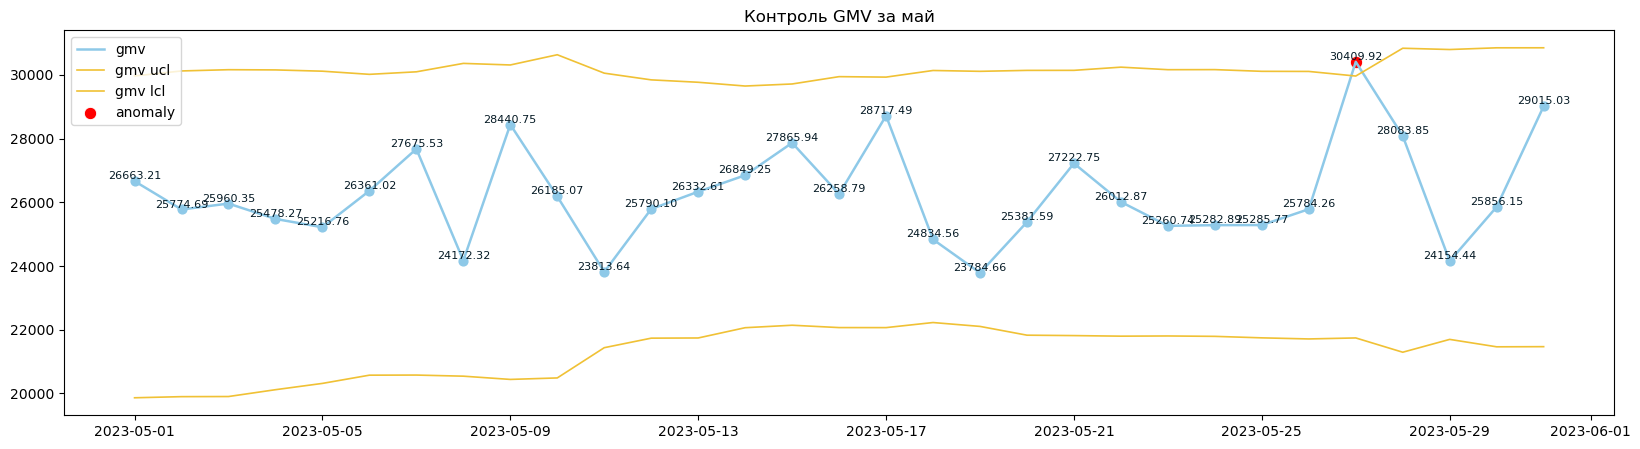

In [810]:
sigma_visualisation(gmv_3sigma, 'gmv', 'Контроль GMV за май')

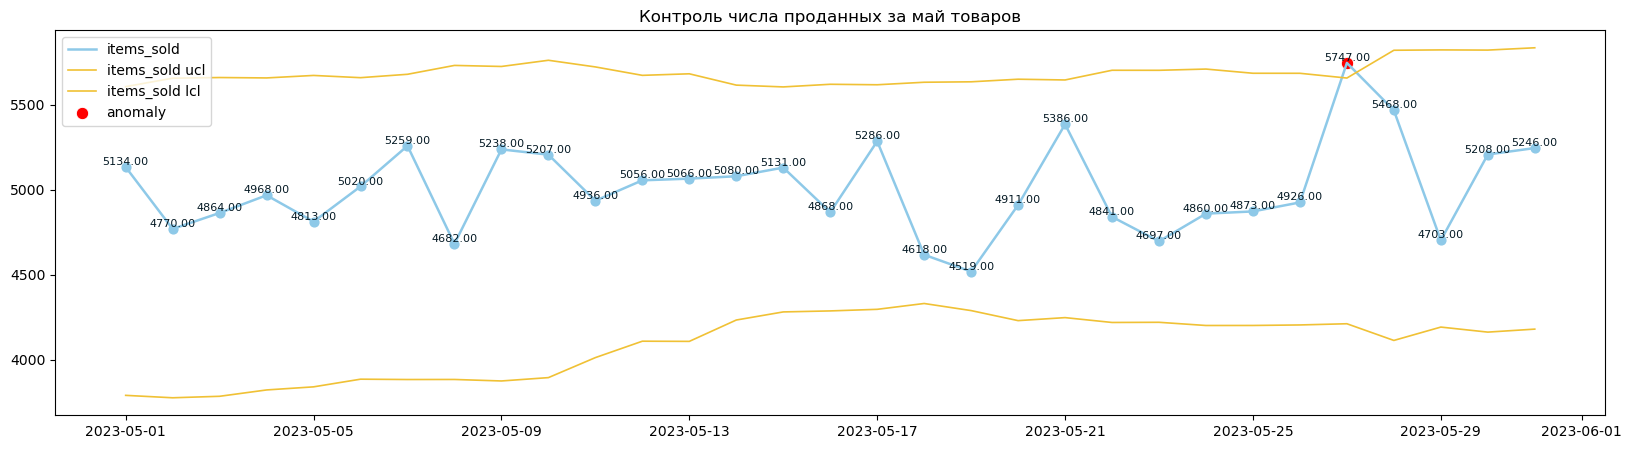

In [811]:
sigma_visualisation(items_3sigma, 'items_sold', 'Контроль числа проданных за май товаров')

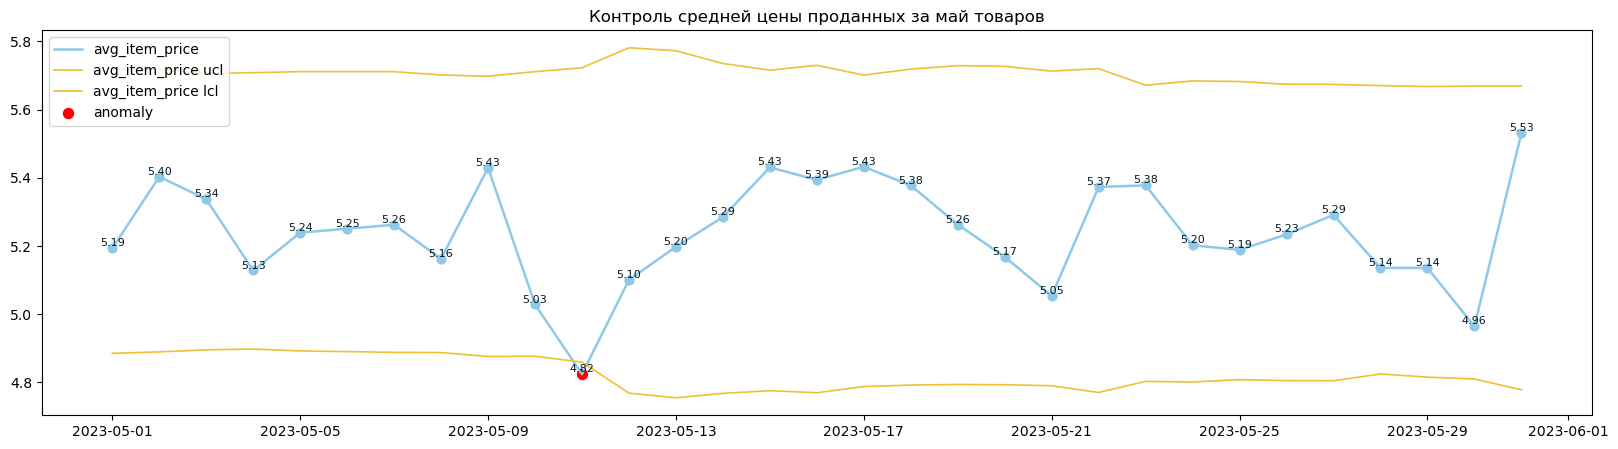

In [812]:
sigma_visualisation(avg_price_3sigma, 'avg_item_price', 'Контроль средней цены проданных за май товаров')

#### 3. Дельта-ряды — 2 балла

1) Рассчитайте дельты значений текущего дня с предыдущим для каждой метрики, затем примените к полученным дельтам правило 3σ:
- gmv;
- items_sold;
- avg_item_price.

Расчет производите на всем датасете. В этом пункте вы имитируете онлайн-мониторинг, поэтому проверка проводится для каждой даты, а границы контроля рассчитываются за последние 28 дней до самой даты. 

2) Постройте графики: дельты метрики + границы контроля + выделенные аномалии.

In [813]:
# your code is here
df['gmv_delta']=df['gmv'].diff()
df['avg_item_price_delta']=df['avg_item_price'].diff()
df['items_sold_delta']=df['items_sold'].diff()

In [814]:
df.head()

,date,items_sold,gmv,avg_item_price,month,gmv_delta,avg_item_price_delta,items_sold_delta
0,2023-01-01,2907,14944.41,5.140836,January,NaN,NaN,NaN
1,2023-01-02,3030,16065.13,5.302023,January,1120.72,0.161187,123.0
2,2023-01-03,3070,17170.30,5.592932,January,1105.17,0.290908,40.0
3,2023-01-04,2708,14367.19,5.305462,January,-2803.11,-0.287470,-362.0
4,2023-01-05,3177,16918.53,5.325316,January,2551.34,0.019855,469.0


In [815]:
gmv_delta=get_3_sigma_cl(df, 'gmv_delta')
gmv_delta.query('is_anomaly_gmv_delta==True')

,date,items_sold,gmv,avg_item_price,month,gmv_delta,avg_item_price_delta,items_sold_delta,gmv_delta_mean,gmv_delta_ssd,gmv_delta_ucl,gmv_delta_lcl,is_anomaly_gmv_delta
243,2023-09-01,4173,21620.90,5.181141,September,-6437.26,-0.158186,-1082.0,124.385357,2015.026693,6169.465437,-5920.694722,True
283,2023-10-11,3637,18976.94,5.217745,October,-3545.92,0.034118,-708.0,-42.022143,852.951522,2516.832423,-2600.876709,True


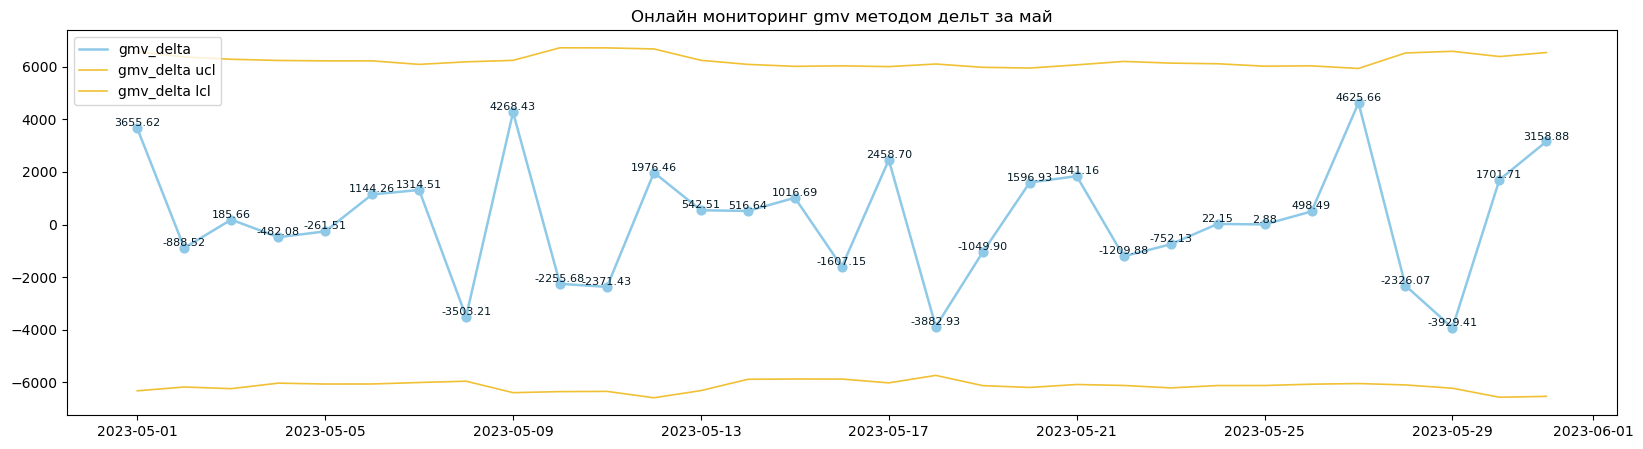

In [816]:
sigma_visualisation(gmv_delta, 'gmv_delta', 'Онлайн мониторинг gmv методом дельт за май')

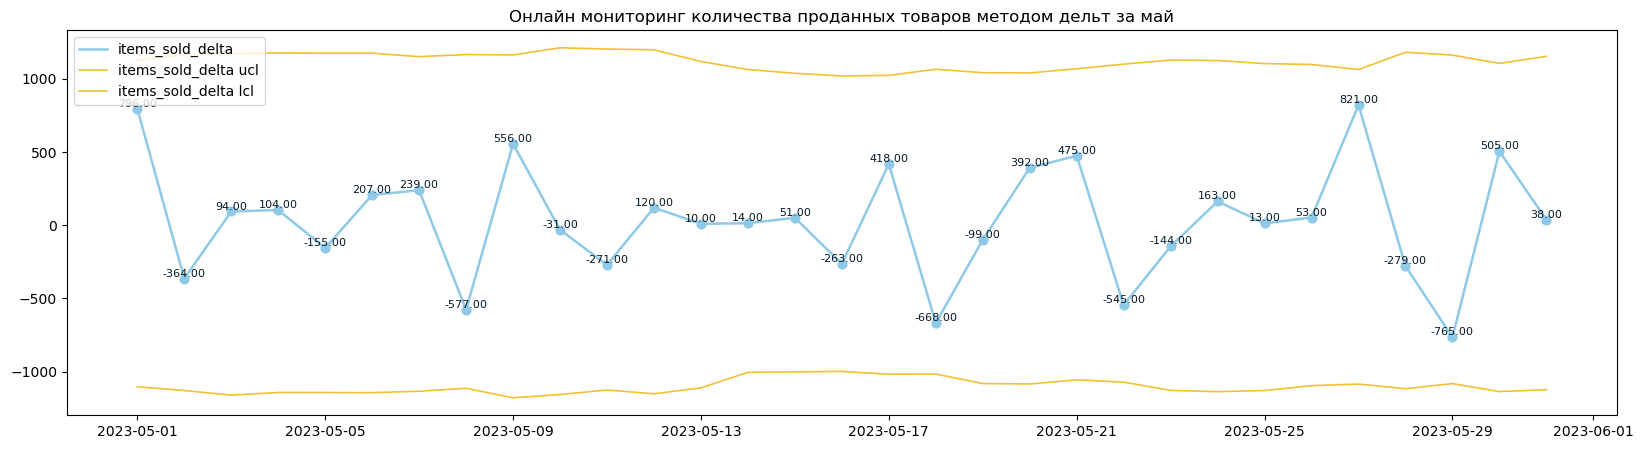

In [839]:
items_sold_delta=get_3_sigma_cl(df, 'items_sold_delta')
sigma_visualisation(items_sold_delta, 'items_sold_delta', title='Онлайн мониторинг количества проданных товаров методом дельт за май')

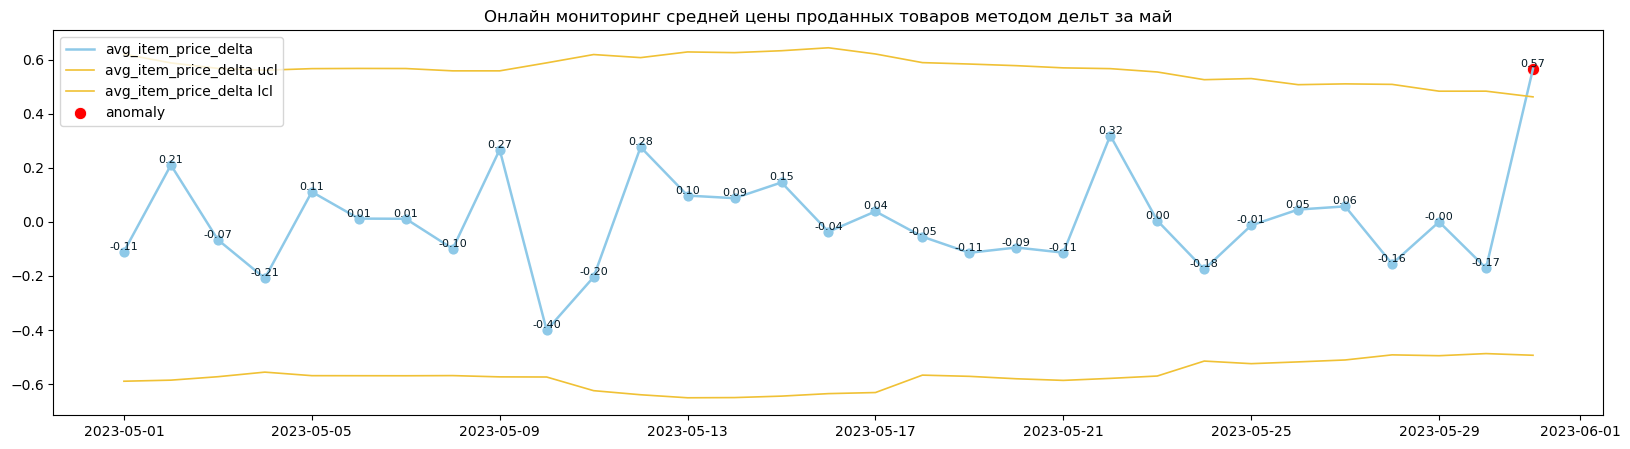

In [817]:
avg_item_price_delta=get_3_sigma_cl(df, 'avg_item_price_delta')
sigma_visualisation(avg_item_price_delta, 'avg_item_price_delta', title='Онлайн мониторинг средней цены проданных товаров методом дельт за май')

#### 4. Generalized ESD — 2 балла

1) Реализуйте Generalized ESD. Обратите внимание, с какими данными работает метод — онлайн или батч? Учтите это в реализации.
2) Найдите аномалии для дельт каждой метрики ЗА МАЙ (используйте данные, полученные на прошлом шаге):
- gmv;
- items_sold;
- avg_item_price.
3) Сравните результаты с правилом 3σ на дельтах: разошлись ли методы?

*Советую обернуть Generalized ESD в функцию, она пригодится на следующем шаге.*

In [819]:
df.head()

,date,items_sold,gmv,avg_item_price,month,gmv_delta,avg_item_price_delta,items_sold_delta
0,2023-01-01,2907,14944.41,5.140836,January,NaN,NaN,NaN
1,2023-01-02,3030,16065.13,5.302023,January,1120.72,0.161187,123.0
2,2023-01-03,3070,17170.30,5.592932,January,1105.17,0.290908,40.0
3,2023-01-04,2708,14367.19,5.305462,January,-2803.11,-0.287470,-362.0
4,2023-01-05,3177,16918.53,5.325316,January,2551.34,0.019855,469.0


In [820]:
#метод Generalized ESD работает с ретроспективными данным из период, поэтому среднее и стандартное отклонение я считаю только за май
def get_gesd(df, metric, alpha=0.05, month=None):
    k=np.floor(df[df['month']==month].shape[0]*0.1)
    candidates=[]

    df_gesd=df[df['month']==month].copy()

    i=0
    while i<k:
        n=len(df_gesd)
        mean=df_gesd[metric].mean()
        std=df_gesd[metric].std()
       

        df_gesd['G']=(df_gesd[metric]-mean).abs()/std
        id_G_max=df_gesd['G'].idxmax()
        G_max=df_gesd.G.loc[id_G_max]
    
    
        tcrit=t.ppf(1-alpha/(2*n), df=n-2)
        Gcrit=((n-1)/np.sqrt(n))*np.sqrt((tcrit**2) / (n - 2 + tcrit**2))

        candidates.append({'index':id_G_max, 'value':G_max, 'Gcrit':Gcrit, 'is_outlier': G_max>Gcrit })
        
        df_gesd = df_gesd.drop(id_G_max, axis=0)
        i=i+1
   
    return  candidates
    

In [821]:
gmv_gesd=get_gesd(df, 'gmv_delta', alpha=0.05, month='May')
gmv_gesd

[{'index': np.int64(146),
  'value': np.float64(1.9740180235114948),
  'Gcrit': np.float64(2.9235705613300507),
  'is_outlier': np.False_},
 {'index': np.int64(128),
  'value': np.float64(1.987262417661394),
  'Gcrit': np.float64(2.908473059722726),
  'is_outlier': np.False_},
 {'index': np.int64(148),
  'value': np.float64(1.910886616184932),
  'Gcrit': np.float64(2.8927047112054254),
  'is_outlier': np.False_}]

In [822]:
items_sold_gesd=get_gesd(df, 'items_sold_delta', alpha=0.05, month='May')
items_sold_gesd

[{'index': np.int64(148),
  'value': np.float64(2.0203215188216945),
  'Gcrit': np.float64(2.9235705613300507),
  'is_outlier': np.False_},
 {'index': np.int64(146),
  'value': np.float64(2.0643043939039063),
  'Gcrit': np.float64(2.908473059722726),
  'is_outlier': np.False_},
 {'index': np.int64(120),
  'value': np.float64(2.2067091514457973),
  'Gcrit': np.float64(2.8927047112054254),
  'is_outlier': np.False_}]

In [841]:
avg_item_price_gesd=get_gesd(df, 'avg_item_price_delta', alpha=0.05, month='May')
avg_item_price_gesd

[{'index': np.int64(150),
  'value': np.float64(2.9637754585880907),
  'Gcrit': np.float64(2.9235705613300507),
  'is_outlier': np.True_},
 {'index': np.int64(129),
  'value': np.float64(2.4323000479818626),
  'Gcrit': np.float64(2.908473059722726),
  'is_outlier': np.False_},
 {'index': np.int64(141),
  'value': np.float64(2.1892102296435874),
  'Gcrit': np.float64(2.8927047112054254),
  'is_outlier': np.False_}]

In [824]:
df.loc[150,:] #эта точка была также определена как аномалия в пункте 3 для avg_item_price

date                    2023-05-31 00:00:00
items_sold                             5246
gmv                                29015.03
avg_item_price                     5.530886
month                                   May
gmv_delta                           3158.88
avg_item_price_delta               0.566188
items_sold_delta                       38.0
Name: 150, dtype: object

**Если смотреть по gmv и items_sold, то первый выброс в gesd совпадает с тем, что было найдено правилом 3 сигм, а именно данные за 2023-05-27. По avg_item_price данные совсем разошлись.**

#### 5. STL-разложение — 2 балла

1) Для каждой метрики выполните STL-разложение с недельной сезонностью (7 дней) на данных всего датасета:
- gmv;
- items_sold;
- avg_item_price.

Используйте STL из библиотеки statsmodels (уже есть в импортах).
  
2) Для каждой метрики визуализируйте компоненты: тренд, сезонность, остатки (на всем датасете).

4) На остатках примените Generalized ESD, можете использовать функцию из прошлого шага. Это упражнение проделываем только на данных ЗА МАЙ.

5) Подумайте, для каждой ли метрики имеет смысл использовать STL, везде ли визуально присутствуют тренд и недельная сезонность?

In [825]:
# your code is here
def get_stl(df, metric, period=7):
    ts = df.set_index('date')[metric]
    stl = STL(ts, period=period, robust=True)
    stl_result = stl.fit()

    return stl_result

In [826]:
def get_stl_viz(stl_result, metric):
    trend = stl_result.trend
    seasonal = stl_result.seasonal
    resid = stl_result.resid
    observed = stl_result.observed

    fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
    
    axes[0].plot(observed, label='Observed')
    axes[0].legend(loc='upper left')
    
    axes[1].plot(trend, color='orange', label='Trend')
    axes[1].legend(loc='upper left')
    
    axes[2].plot(seasonal, color='green', label='Seasonal')
    axes[2].legend(loc='upper left')
    
    axes[3].plot(resid, color='red', label='Residuals')
    axes[3].legend(loc='upper left')

    fig.suptitle(f'{metric} STL', fontsize=14)
    plt.tight_layout()
    plt.show()

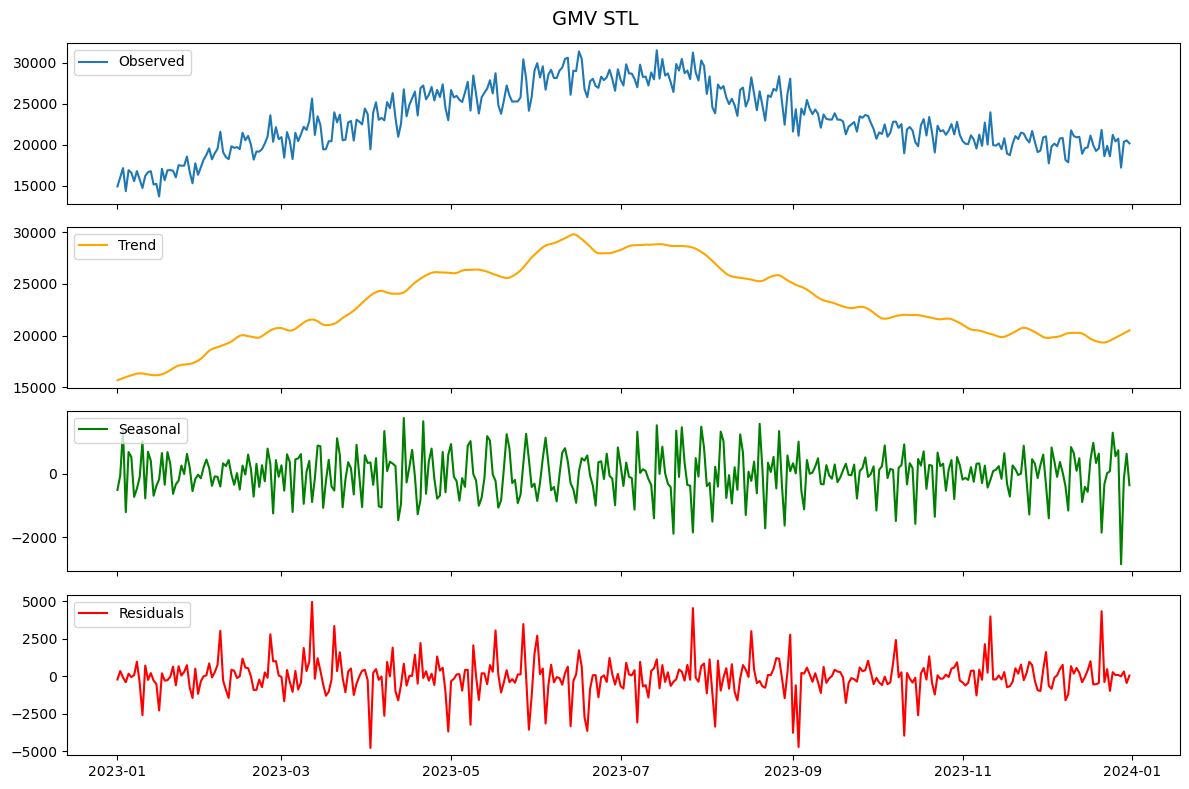

In [827]:
gmv_stl=get_stl(df, 'gmv')
get_stl_viz(gmv_stl, 'GMV')

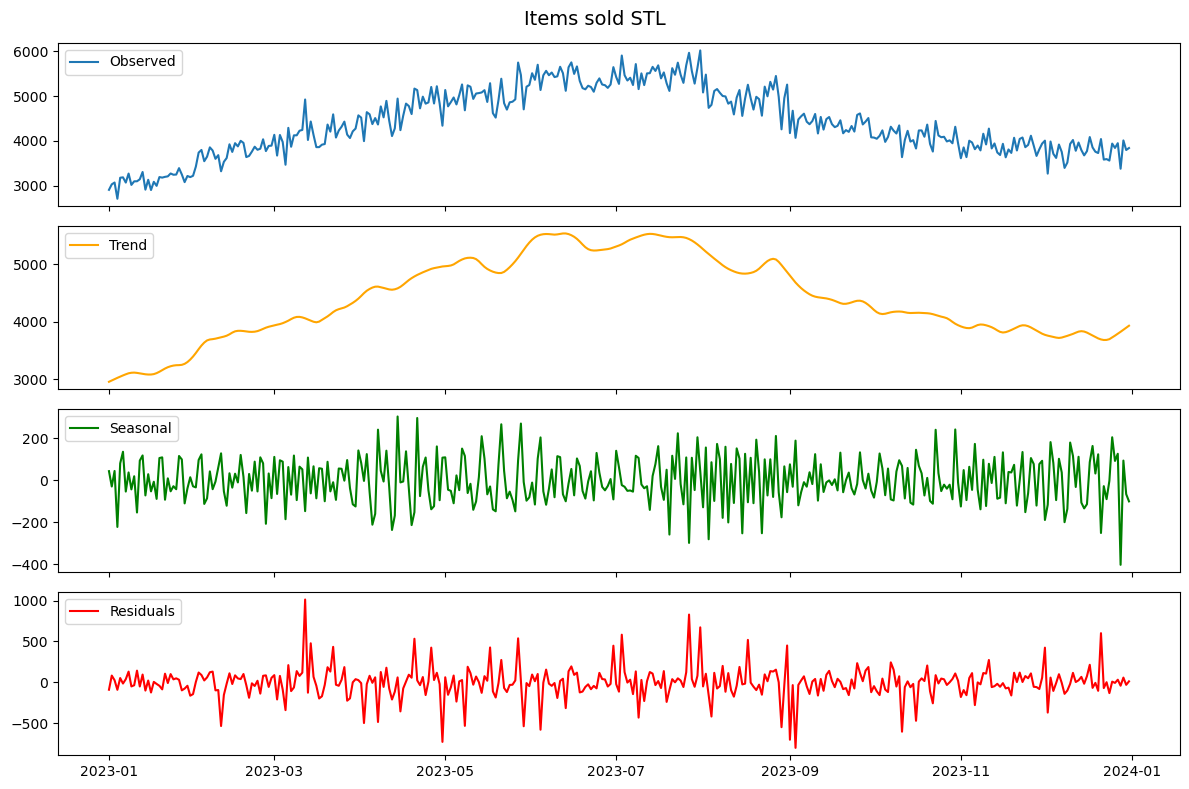

In [828]:
items_sold_stl=get_stl(df, 'items_sold')
get_stl_viz(items_sold_stl, 'Items sold')

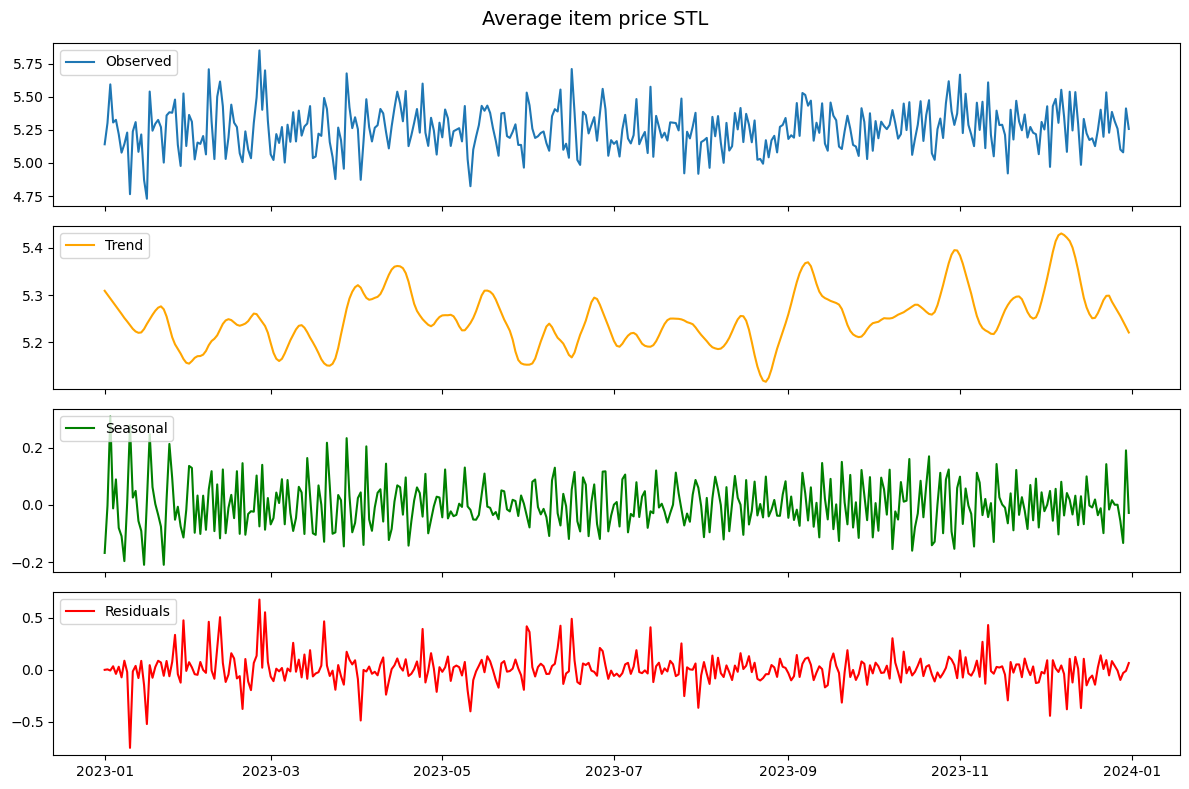

In [829]:
avg_item_price_stl=get_stl(df, 'avg_item_price')
get_stl_viz(avg_item_price_stl, 'Average item price')

In [830]:
df_gmv_resid=gmv_stl.resid.reset_index()
df_gmv_resid['month']=pd.to_datetime(df_gmv_resid['date']).dt.month_name()
gmv_stl_gesd=get_gesd(df_gmv_resid, 'resid', alpha=0.05, month='May')
gmv_stl_gesd

[{'index': np.int64(148),
  'value': np.float64(2.506104623734356),
  'Gcrit': np.float64(2.9235705613300507),
  'is_outlier': np.False_},
 {'index': np.int64(146),
  'value': np.float64(2.673384331024933),
  'Gcrit': np.float64(2.908473059722726),
  'is_outlier': np.False_},
 {'index': np.int64(127),
  'value': np.float64(2.8750135109290955),
  'Gcrit': np.float64(2.8927047112054254),
  'is_outlier': np.False_}]

In [831]:
df_items_sold_resid=items_sold_stl.resid.reset_index()
df_items_sold_resid['month']=pd.to_datetime(df_items_sold_resid['date']).dt.month_name()
items_sold_stl_gesd=get_gesd(df_items_sold_resid, 'resid', alpha=0.05, month='May')

In [832]:
df_avg_item_price_resid=avg_item_price_stl.resid.reset_index()
df_avg_item_price_resid['month']=pd.to_datetime(df_avg_item_price_resid['date']).dt.month_name()
get_gesd(df_avg_item_price_resid, 'resid', alpha=0.05, month='May')

[{'index': np.int64(150),
  'value': np.float64(3.090340743627028),
  'Gcrit': np.float64(2.9235705613300507),
  'is_outlier': np.True_},
 {'index': np.int64(130),
  'value': np.float64(3.3581095931550045),
  'Gcrit': np.float64(2.908473059722726),
  'is_outlier': np.True_},
 {'index': np.int64(129),
  'value': np.float64(2.1653033919170377),
  'Gcrit': np.float64(2.8927047112054254),
  'is_outlier': np.False_}]

**В ecom-приложении доставки FMCG-товаров сезонность будет присутствовать во многих метриках, так и на среднюю цену и на количество продаваемых товаров влияет поведение покупателей: например перед праздниками люди могут покупать товары из более дорогих сегментов, чтобы порадовать себя. А вот метрики, связанные например с мониторингом инфраструктуры (ошибки серверов, задержи запросов, количество инцидентов) не имеют ярко вырженной сезонности. Поведение пользователей конечно влияет на эти показатели, но это сезонность скорее не календарная.** 

#### 6. EWMA — 2 балла

1) Реализуйте метод EWMA для каждой метрики:
- gmv;
- items_sold;
- avg_item_price.

Сглаженная статистика считается рекуррентно с параметром $\lambda = 0.2$:

$$
z_t = \lambda x_t + (1-\lambda)\, z_{t-1}, \qquad z_0 = x_0,
$$

где $x_t$ — исходное дневное значение метрики. В pandas это делает [встроенная функция экспоненциального сглаживания](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.ewm.html) — обратите внимание на параметр `adjust=False`, именно он дает рекуррентную форму выше.

Контрольные границы задаются как

$$
\mu_t \pm L\,\sigma_t \sqrt{\frac{\lambda}{2-\lambda}}, \qquad L = 3.
$$

Здесь $\mu_t$ и $\sigma_t$ — среднее и стандартное отклонение **исходного ряда $x_t$**, а не сглаженного $z_t$, посчитанные на скользящем окне 28 дней. Множитель $\sqrt{\lambda/(2-\lambda)}$ — асимптотическое приближение отношения дисперсии сглаженной статистики к дисперсии сырых наблюдений: он уже учитывает, что $z_t$ колеблется меньше, чем $x_t$, поэтому подставлять в формулу разброс самого $z_t$ нельзя — сжатие применится дважды, и коридор получится слишком узким.

Окно для $\mu_t$ и $\sigma_t$ должно заканчиваться на предыдущем дне (`.rolling(28).mean().shift(1)`), иначе текущее наблюдение попадёт в собственную оценку разброса и аномалия спрячет сама себя.

2) Постройте графики: сглаженная метрика + границы контроля + выделенные аномалии.
3) Напишите, какой из подходов вам больше всего понравился для онлайн-мониторинга, а какой — для ретроспективного анализа, и почему. Тут нет правильного ответа :)

In [833]:
def get_EWMA(df, metric, window=28, lambda_=0.2):
    df_ewma=df.copy()
    df_ewma[f'{metric}_EWMA']=df_ewma[metric].ewm(alpha=lambda_, adjust=False).mean()
    

    df_ewma[f'{metric}_mean'] = df_ewma[metric].shift(1).rolling(window=window, min_periods=window).mean()
    df_ewma[f'{metric}_ssd'] = df_ewma[metric].shift(1).rolling(window=window, min_periods=window).std(ddof=1)
    
    k=(lambda_/(2-lambda_))**0.5
    df_ewma[f'{metric}_ucl']=df_ewma[f'{metric}_mean']+3*k*df_ewma[f'{metric}_ssd']
    df_ewma[f'{metric}_lcl']=df_ewma[f'{metric}_mean']-3*k*df_ewma[f'{metric}_ssd']

    df_ewma[f'is_anomaly_{metric}'] = (df_ewma[f'{metric}_EWMA'] < df_ewma[f'{metric}_lcl']) | (df_ewma[f'{metric}_EWMA'] > df_ewma[f'{metric}_ucl'])

    return df_ewma

In [834]:
EWMA_gmv=get_EWMA(df, 'gmv')

In [835]:
def ewma_visualisation(df, metric, title=None):
    df=df[df['month']=='May'].copy()
    fig, ax = plt.subplots(figsize=(20,5))

    sns.lineplot(data=df, x='date', y=df[f'{metric}_EWMA'], ax=ax, color="#24A3E8", linewidth=1.8, label=f'{metric}_EWMA')

    sns.lineplot(data=df, x='date', y=df[metric], ax=ax, color="#EF9EE9", linewidth=1, label=metric)
    ax.scatter(df['date'], df[metric], color="#EF9EE9", s=30)

        
    sns.lineplot(data=df, x='date', y=df[f'{metric}_ucl'], linewidth=1.4, color="#ECB206", label=f'{metric} ucl')
    sns.lineplot(data=df, x='date', y=df[f'{metric}_lcl'], linewidth=1.4, color="#ECB206", label=f'{metric} lcl')
    sns.scatterplot(data=df[df[f'is_anomaly_{metric}']==True], x='date', y=df[f'{metric}_EWMA'], color='red', s=80, label='anomaly')


    legend=ax.legend()
    legend.set_title('')
    plt.title(title)
    plt.legend(loc='upper left')
    plt.ylabel('')
    plt.xlabel('')
    plt.show()

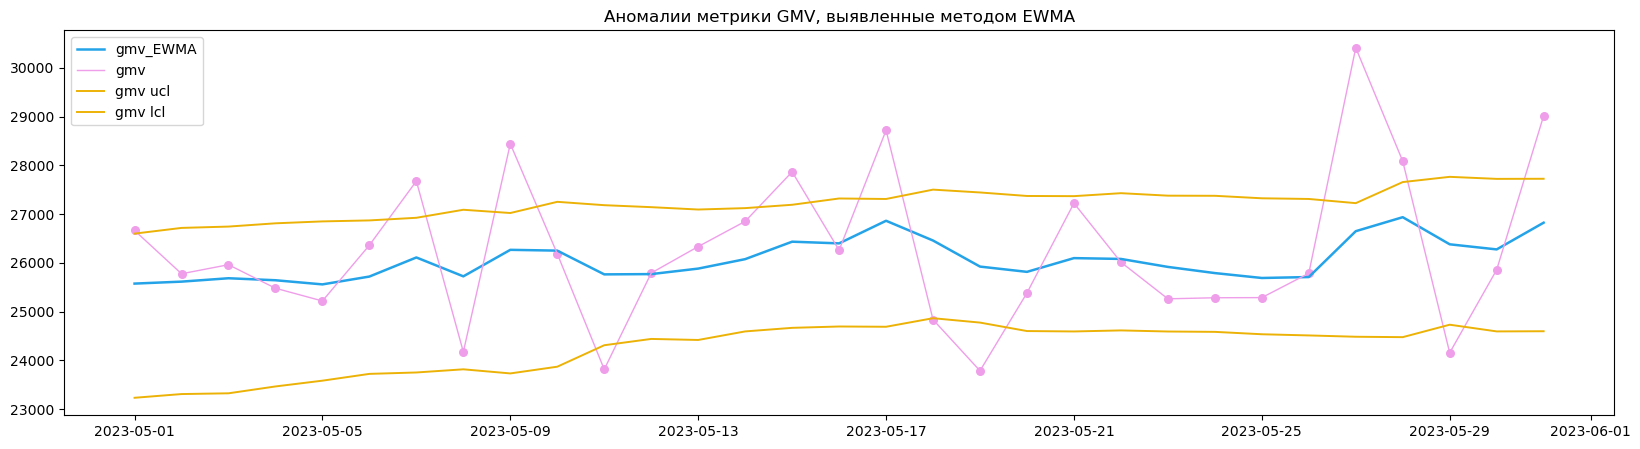

In [836]:
ewma_visualisation(EWMA_gmv, 'gmv', title='Аномалии метрики GMV, выявленные методом EWMA')

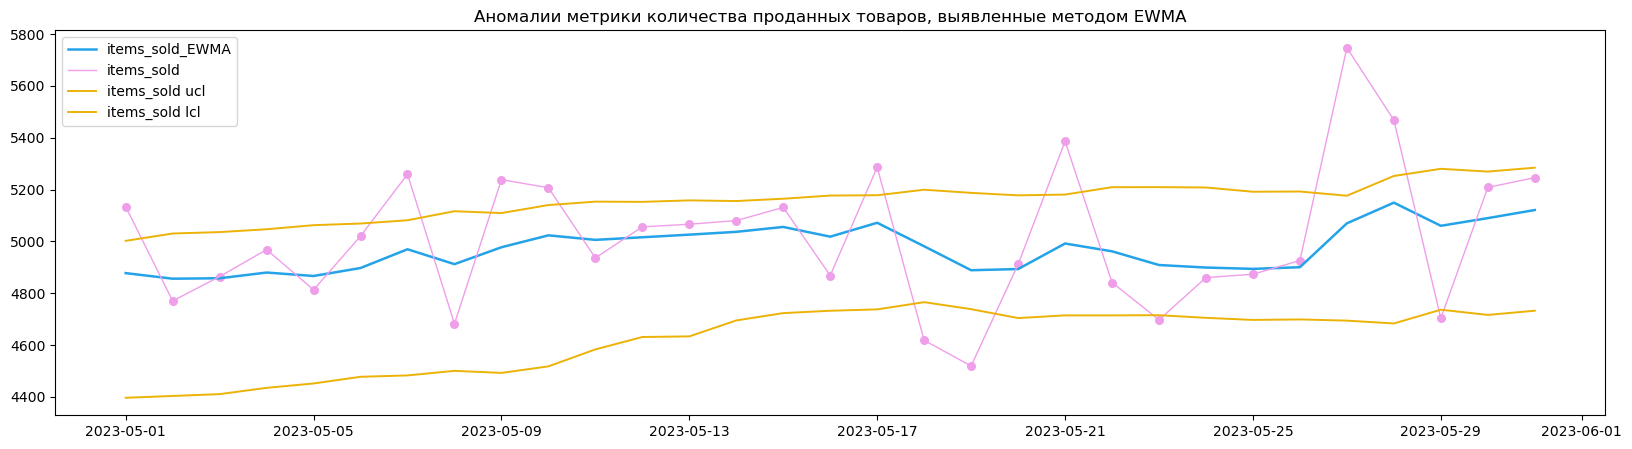

In [837]:
EWMA_items_sold=get_EWMA(df, 'items_sold')
ewma_visualisation(EWMA_items_sold, 'items_sold', title='Аномалии метрики количества проданных товаров, выявленные методом EWMA')

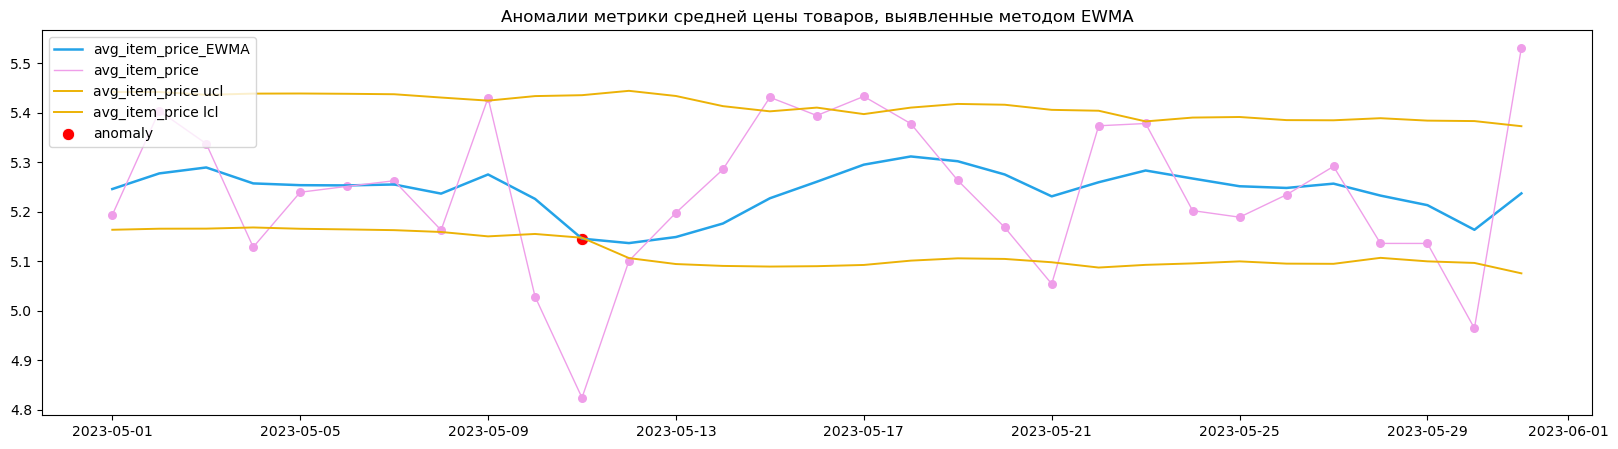

In [838]:
EWMA_avg_item_price=get_EWMA(df, 'avg_item_price')
ewma_visualisation(EWMA_avg_item_price, 'avg_item_price', title='Аномалии метрики средней цены товаров, выявленные методом EWMA')

**Признаюсь честно, считать было интересно, но пока чертовски не понятно какой метод, где использовать. Пока, в части онлайн методов мне нравится, метод 3 сигм: он интуитивно понятен и на моем текущем уровне, я бы смогла объяснить его результат бизнесу. Из ретроспективных методов, интересно выглядит STL-разложение с generalized ESD: разложение помогает лучше увидеть отдельные компоненты ряда, а gesd посчитать аномалии.**